<a href="https://colab.research.google.com/github/dsumathiphd/TYL-Agentic-AI/blob/main/Multi_Agent_Framework_LangGraph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Planner Agent: Preparing workshop agenda

Budget Agent: Total cost = 19000

Resource Agent: Budget exceeded
Replacing an external speaker with internal faculty

Budget Agent: Total cost = 13000

Coordinator Agent: Workshop approved

           FINAL WORKSHOP PLAN
Workshop          : Agentic AI
Duration          : One Day
Students          : 100
Agenda            : Introduction, AI Demo, Hands-on Lab
External Speakers : 1
Internal Faculty  : 1
Maximum Budget    : Rs. 15000
Total Expenditure : Rs. 13000
Remaining Budget  : Rs. 2000
Status            : APPROVED

All validation tests passed successfully!

MERMAID DIAGRAM SOURCE:

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	planner(planner)
	budget_manager(budget_manager)
	resource(resource)
	coordinator(coordinator)
	failure(failure)
	__end__([<p>__end__</p>]):::last
	__start__ --> planner;
	budget_manager -. &nbsp;approved&nbsp; .-> coordinator;
	budget_manager -. &nbsp;failed&nbsp; .-

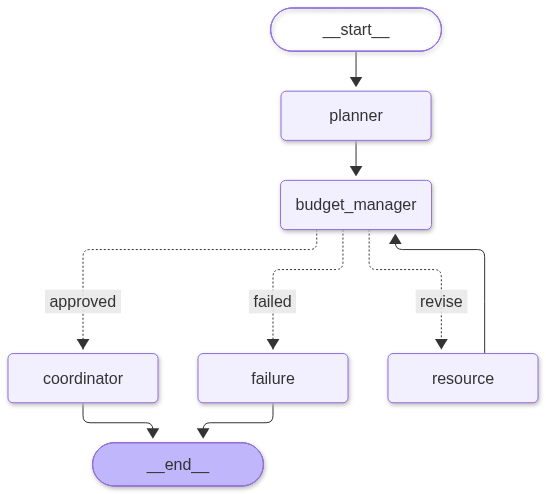

In [1]:
# =====================================================
# LANGGRAPH - MULTI-AGENT WORKSHOP PLANNING SYSTEM
# Google Colab | No API Key | No Ollama | No Paid Credits
# Rule-based agent nodes - No LLM required
# =====================================================

# Step 1: Install LangGraph

%pip install -q langgraph


# Step 2: Import required libraries

from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display


# Step 3: Define shared state

class WorkshopState(TypedDict):
    students: int
    budget: int
    external_speakers: int
    internal_speakers: int
    total_cost: int
    agenda: str
    status: str


# Step 4: Create Planner Agent

def planner_agent(state):

    print("\nPlanner Agent: Preparing workshop agenda")

    return {
        "external_speakers": 2,
        "internal_speakers": 0,
        "agenda": "Introduction, AI Demo, Hands-on Lab"
    }


# Step 5: Create Budget Agent

def budget_agent(state):

    speaker_cost = state["external_speakers"] * 6000
    refreshments = 5000
    materials = 2000

    total = speaker_cost + refreshments + materials

    print("\nBudget Agent: Total cost =", total)

    return {"total_cost": total}


# Step 6: Create Resource Agent

def resource_agent(state):

    print("\nResource Agent: Budget exceeded")
    print("Replacing an external speaker with internal faculty")

    return {
        "external_speakers": state["external_speakers"] - 1,
        "internal_speakers": state["internal_speakers"] + 1
    }


# Step 7: Create Coordinator Agent

def coordinator_agent(state):

    print("\nCoordinator Agent: Workshop approved")

    return {"status": "APPROVED"}


# Step 8: Create failure handling function

def failure_agent(state):

    print("\nBudget is insufficient to conduct the workshop")

    return {"status": "NOT APPROVED"}


# Step 9: Define decision-making function

def check_budget(state):

    if state["total_cost"] <= state["budget"]:
        return "approved"

    elif state["external_speakers"] > 0:
        return "revise"

    else:
        return "failed"


# Step 10: Create LangGraph workflow

workflow = StateGraph(WorkshopState)


# Step 11: Add agent nodes

workflow.add_node("planner", planner_agent)
workflow.add_node("budget_manager", budget_agent)
workflow.add_node("resource", resource_agent)
workflow.add_node("coordinator", coordinator_agent)
workflow.add_node("failure", failure_agent)


# Step 12: Connect the agents

workflow.add_edge(START, "planner")
workflow.add_edge("planner", "budget_manager")

workflow.add_conditional_edges(
    "budget_manager",
    check_budget,
    {
        "approved": "coordinator",
        "revise": "resource",
        "failed": "failure"
    }
)

workflow.add_edge("resource", "budget_manager")
workflow.add_edge("coordinator", END)
workflow.add_edge("failure", END)


# Step 13: Compile the workflow

app = workflow.compile()


# Step 14: Define initial input

initial_state = {
    "students": 100,
    "budget": 15000,
    "external_speakers": 0,
    "internal_speakers": 0,
    "total_cost": 0,
    "agenda": "",
    "status": "PENDING"
}


# Step 15: Execute the multi-agent system

result = app.invoke(initial_state)


# Step 16: Display final workshop plan

print("\n" + "=" * 50)
print("           FINAL WORKSHOP PLAN")
print("=" * 50)

print("Workshop          : Agentic AI")
print("Duration          : One Day")
print("Students          :", result["students"])
print("Agenda            :", result["agenda"])
print("External Speakers :", result["external_speakers"])
print("Internal Faculty  :", result["internal_speakers"])
print("Maximum Budget    : Rs.", result["budget"])
print("Total Expenditure : Rs.", result["total_cost"])
print("Remaining Budget  : Rs.",
      result["budget"] - result["total_cost"])
print("Status            :", result["status"])

print("=" * 50)


# Step 17: Validate the results

assert result["total_cost"] == 13000
assert result["external_speakers"] == 1
assert result["internal_speakers"] == 1
assert result["status"] == "APPROVED"
assert result["total_cost"] <= result["budget"]

print("\nAll validation tests passed successfully!")


# Step 18: Generate Mermaid diagram

print("\nMERMAID DIAGRAM SOURCE:\n")

mermaid_code = app.get_graph().draw_mermaid()

print(mermaid_code)


# Step 19: Display Mermaid diagram

try:
    display(Image(app.get_graph().draw_mermaid_png()))

except Exception as e:
    print("Mermaid image rendering unavailable:", str(e))
    print("Copy the Mermaid source into https://mermaid.live/")


# Verification note:
# End-to-end Colab execution has not been independently tested.
# The assertions above verify the results during execution.